# Chapitre 1 - Exercices 1.7 à 1.12

Ce notebook traite les six derniers exercices du chapitre 1, centrés sur
l'architecture cloud native, le choix entre distribué et mono-nœud, et l'effacement des
données :

- **1.7** : dimensionner un cache local devant un object store (calcul et mini-lab) ;
- **1.8** : une machine ou un cluster ? (ordres de grandeur et métrique COST) ;
- **1.9** : réessais et idempotence, combien de doublons ? (probabilités et
  simulation) ;
- **1.10** : démarrages à froid et coût du serverless (calcul et simulation) ;
- **1.11** : l'intervalle optimal des points de reprise (démonstration et simulation) ;
- **1.12** : effacer dans un journal immuable, compaction ou crypto-shredding
  (calcul et mini-lab).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import architecture as ar
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.sim import Network, Node

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## Exercice 1.7 : dimensionner un cache local devant un object store

**Énoncé.** Un moteur analytique cloud native lit des blocs de 4 Mo. Lus depuis l'object
store, ils coûtent en moyenne 70 ms ; depuis le SSD local du nœud de calcul, 2 ms. Les
accès aux 100 000 blocs de l'entrepôt suivent une loi de Zipf d'exposant $s = 1{,}1$.

1. Quel taux de succès $h$ du cache faut-il pour que la lecture moyenne d'un bloc tombe
   sous 10 ms ?
2. Un cache **idéal** garderait les $C$ blocs les plus populaires. Exprimer son taux de
   succès en fonction de $C$, et en déduire la taille minimale.
3. Un vrai cache LRU fait moins bien. Trouver par simulation la taille nécessaire.
4. Chaque nœud a 1,9 To de SSD. Combien de nœuds faut-il au minimum pour que le cache
   réparti tienne, si chaque bloc est caché sur un seul nœud ?

**Rappels.** Lecture moyenne $= h\,L_{ssd} + (1 - h)\,L_{obj}$ ; loi de Zipf : la clé de
rang $i$ a une probabilité proportionnelle à $1/i^s$ ; cache LRU (`ar.LRUCache`), accès
Zipf (`ar.zipf_keys`) (cours 3, section 5 ; section *Separation of storage and compute*).

**Solution.**

*1.* $h \cdot 2 + (1 - h) \cdot 70 \le 10 \iff 68\,h \ge 60 \iff h \ge 0{,}882$.

*2.* Le cache idéal capture la masse des $C$ premiers rangs :
$h(C) = \sum_{i \le C} i^{-s} / \sum_{i \le N} i^{-s}$. On cherche le plus petit $C$ tel que
$h(C) \ge 0{,}882$ (calcul ci-dessous) : environ 8 700 blocs, moins de 9 % de l'entrepôt.
C'est la force de la loi de Zipf : une petite tête de blocs très populaires concentre
l'essentiel des accès.

*3.* La simulation (ci-dessous) donne une taille LRU environ deux fois plus grande, de
l'ordre de 18 000 blocs : LRU garde aussi des blocs peu populaires récemment lus, au
détriment de blocs plus populaires. (La courbe LRU plafonne vers 92 % : sur une trace
finie, le premier accès à chacun des nombreux blocs rares est un échec inévitable.)

*4.* 18 000 blocs de 4 Mo = 72 Go : un seul nœud suffit largement, son SSD de 1,9 To
pourrait même cacher tout l'entrepôt (400 Go). La vraie question devient alors : pourquoi
ne pas tout cacher ? Parce qu'un nouveau nœud (élasticité, remplacement après panne)
démarre à froid : le cache est un état éphémère qu'il faut réchauffer (cours 3).

**Vérification.**

h requis = 0.882 ; cache idéal : C = 8 731 blocs


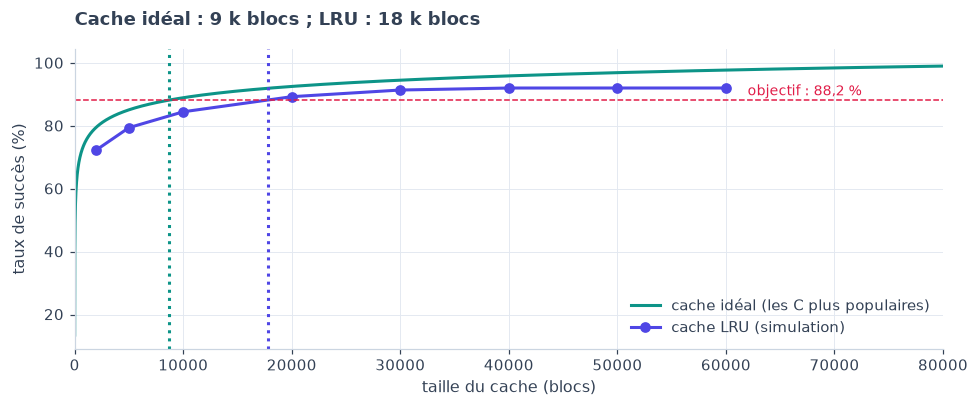

In [2]:
N, s, L_obj, L_ssd = 100_000, 1.1, 70.0, 2.0
h_target = (L_obj - 10) / (L_obj - L_ssd)
w = 1 / np.arange(1, N + 1) ** s
h_ideal = np.cumsum(w) / w.sum()
C_ideal = int(np.searchsorted(h_ideal, h_target)) + 1
print(f"h requis = {h_target:.3f} ; cache idéal : C = {fmt(C_ideal)} blocs")

trace = ar.zipf_keys(N, 400_000, s=s, seed=1)
sizes = [2_000, 5_000, 10_000, 20_000, 30_000, 40_000, 50_000, 60_000]
lru = []
for C in sizes:
    c = ar.LRUCache(C)
    for k in trace[:100_000]:                          # échauffement
        c.get(int(k))
    c.hits = c.misses = 0
    for k in trace[100_000:]:
        c.get(int(k))
    lru.append(c.hit_ratio)
C_lru = np.interp(h_target, lru, sizes)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(np.arange(1, N + 1), h_ideal * 100, color=TEAL, label="cache idéal (les C plus populaires)")
ax.plot(sizes, np.array(lru) * 100, "o-", color=INDIGO, label="cache LRU (simulation)")
ax.axhline(h_target * 100, color=ROSE, ls="--", lw=1); ax.text(62_000, h_target * 100 + 1.5, "objectif : 88,2 %", color=ROSE, fontsize=9)
ax.axvline(C_ideal, color=TEAL, ls=":"); ax.axvline(C_lru, color=INDIGO, ls=":")
ax.set_xlim(0, 80_000); ax.set_xlabel("taille du cache (blocs)"); ax.set_ylabel("taux de succès (%)")
ax.set_title(f"Cache idéal : {C_ideal / 1000:.0f} k blocs ; LRU : {C_lru / 1000:.0f} k blocs")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

Les deux tailles confirment le raisonnement : 9 % des blocs pour le cache idéal, le double
pour LRU. À 4 Mo par bloc, cela reste quelques dizaines de gigaoctets, qui tiennent
sans peine sur le SSD d'un seul nœud.

> **À retenir.** Le taux de succès requis se déduit des deux latences ; la taille du cache
> se déduit de la distribution des accès, et LRU demande environ deux fois la taille d'un
> cache idéal. Avec des accès concentrés (Zipf), quelques pour cent des données suffisent.

## Exercice 1.8 : une machine ou un cluster ?

**Énoncé.** Une équipe doit exécuter chaque heure une requête qui parcourt un historique
de 2 To au format colonne, dont la requête ne lit que 3 colonnes sur 30 (de tailles
égales), avec un taux de compression de 4 sur ces colonnes.

1. Combien d'octets la requête lit-elle sur disque ? Combien de temps prend-elle sur une
   machine dotée de 4 SSD NVMe à 3 Go/s chacun, si le processeur suit ?
2. Le processeur décompresse et agrège à 1,5 Go/s de données décompressées par cœur. Avec
   32 cœurs, qui limite : le disque ou le processeur ?
3. Un cluster de calcul lit les mêmes données depuis un object store, à 10 Gb/s de réseau
   par nœud, et son moteur générique fait 4 fois plus de travail processeur qu'un moteur
   mono-nœud optimisé. Combien de nœuds de 32 cœurs faut-il pour faire mieux que la
   machine unique ?
4. Un banc d'essai a mesuré pour le cluster : 1 nœud 410 s, 2 nœuds 215 s, 4 nœuds 118 s,
   8 nœuds 69 s, 16 nœuds 45 s, 32 nœuds 38 s. Le programme mono-nœud optimisé prend 50 s.
   Quelle est la COST du cluster (en nœuds) ?

**Rappels.** Métrique COST : plus petite configuration qui bat le programme mono-thread
(ici mono-nœud) de référence (`ar.cost_metric`) ; le débit d'un traitement est le minimum
des débits de ses étapes ; amener le calcul aux données (cours 4, section 3 ; section
*Problems with Distributed Systems*).

**Solution.**

*1.* 3 colonnes sur 30 : 200 Go décompressés, soit 50 Go compressés lus. À 12 Go/s :
**4,2 s** de lecture.

*2.* Processeur : 200 Go décompressés à $32 \times 1{,}5 = 48$ Go/s, soit **4,2 s**
également. Les deux sont équilibrés : environ 4 à 5 secondes par requête, une machine
suffit largement pour une requête par heure.

*3.* Par nœud : réseau 10 Gb/s = 1,25 Go/s compressés, soit 5 Go/s décompressés ;
processeur $48 / 4 = 12$ Go/s utiles. Le réseau limite à 5 Go/s par nœud. Pour battre
48 Go/s (le goulot de la machine unique, en équilibre avec ses disques), il faut au moins
$\lceil 48/5 \rceil = 10$ nœuds, soit 320 cœurs, sans compter la coordination.

*4.* Le premier temps inférieur à 50 s est celui de 16 nœuds (45 s) : **COST = 16 nœuds**.
Au-delà, le gain s'effondre (38 s à 32 nœuds) : la coordination domine.

**Vérification numérique** et graphique.

lu : 50 Go ; disque 4.2 s ; CPU 4.2 s ; cluster : 5 Go/s utiles par nœud -> 10 nœuds pour égaler
COST = 16 nœuds


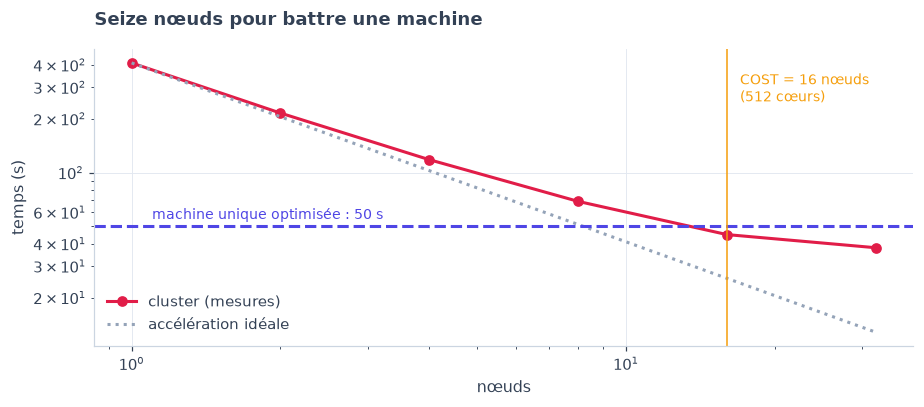

In [3]:
read_gb = 2000 * 3 / 30 / 4
t_disk = read_gb / (4 * 3)
t_cpu = 2000 * 3 / 30 / (32 * 1.5)
per_node = min(10 / 8 * 4, 32 * 1.5 / 4)
nodes_needed = math.ceil(32 * 1.5 / per_node)
print(f"lu : {read_gb:.0f} Go ; disque {t_disk:.1f} s ; CPU {t_cpu:.1f} s ; "
      f"cluster : {per_node:.0f} Go/s utiles par nœud -> {nodes_needed} nœuds pour égaler")
ns = [1, 2, 4, 8, 16, 32]
times = [410, 215, 118, 69, 45, 38]
print("COST =", ar.cost_metric(ns, times, 50), "nœuds")
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.loglog(ns, times, "o-", color=ROSE, label="cluster (mesures)")
ax.loglog(ns, 410 / np.array(ns), ":", color=GRAY, label="accélération idéale")
ax.axhline(50, color=INDIGO, ls="--"); ax.text(1.1, 55, "machine unique optimisée : 50 s", color=INDIGO, fontsize=9)
ax.axvline(16, color=AMBER, lw=1); ax.text(17, 250, "COST = 16 nœuds\n(512 cœurs)", color=AMBER, fontsize=9)
ax.set_xlabel("nœuds"); ax.set_ylabel("temps (s)"); ax.set_title("Seize nœuds pour battre une machine")
ax.legend(loc="lower left"); plt.tight_layout(); plt.show()

Il faut 512 cœurs répartis pour battre 32 cœurs bien employés : c'est l'ordre de grandeur
que la métrique COST met en évidence dans la littérature. La machine unique est aussi
beaucoup plus simple à exploiter.

> **À retenir.** Avant de distribuer, estimer ce que fait une seule machine bien utilisée
> (format colonne, compression, disques locaux rapides). Un cluster qui lit par le réseau
> avec un moteur générique doit d'abord rattraper son surcoût : sa COST se compte souvent en
> dizaines de nœuds.

## Exercice 1.9 : réessais et idempotence, combien de doublons ?

**Énoncé.** Un client envoie une requête de débit à un serveur ; chaque message (requête
ou réponse) est perdu indépendamment avec probabilité $p$. Le client réessaie, après
expiration de son délai, jusqu'à recevoir une réponse.

1. Quelle est la probabilité $q$ qu'une tentative réussisse (le client reçoit la
   réponse) ? Le nombre moyen de tentatives ?
2. Le serveur est naïf (il exécute chaque requête reçue). Montrer que le nombre moyen
   d'exécutions par opération vaut $1/(1-p)$.
3. Application à $p = 0{,}2$ (comparer au cours 4) et à $p = 0{,}01$.
4. Vérifier par simulation, puis montrer qu'une clé d'idempotence ramène le nombre
   d'exécutions à exactement 1.

**Rappels.** Délai d'attente ambigu : le client ne sait pas si sa requête a été traitée ;
un serveur idempotent ignore une clé déjà vue (cours 4, section 2 ; section *Problems with
Distributed Systems*).

**Solution.**

*1.* Une tentative réussit si la requête **et** la réponse passent : $q = (1-p)^2$. Le
nombre de tentatives suit une loi géométrique : $E[T] = 1/q = 1/(1-p)^2$.

*2.* Chaque tentative exécute l'opération si la requête arrive, avec probabilité $1-p$,
indépendamment du reste. Par l'identité de Wald, $E[\text{exécutions}] = E[T]\,(1-p)
= (1-p)/(1-p)^2 = 1/(1-p)$.

*3.* $p = 0{,}2$ : $E[T] = 1{,}5625$ et $1{,}25$ exécution par opération, soit 25 % de
doublons. Le cours 4 a mesuré 1 559 tentatives et 1 236 débits pour 1 000 opérations :
conforme. $p = 0{,}01$ : $1{,}0101$ exécution, soit encore 1 doublon pour 100 opérations,
ce qui, sur des millions de paiements, reste inacceptable.

**Vérification par simulation** sur `ddia.sim`, pour plusieurs taux de perte.

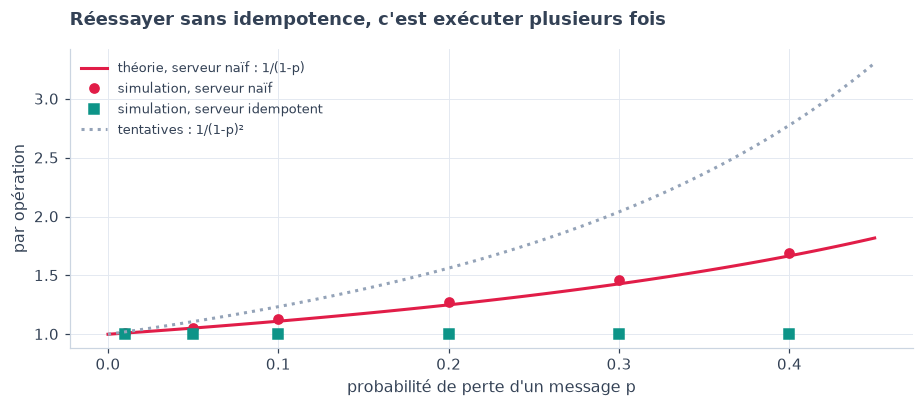

serveur,idempotent,naïf
p,,
0.01,1.0,1.007
0.05,1.0,1.052
0.10,1.0,1.125
0.20,1.0,1.275
0.30,1.0,1.458
0.40,1.0,1.690


In [4]:
class Server(Node):
    def __init__(self, name, idempotent):
        super().__init__(name)
        self.idempotent, self.executions, self.seen = idempotent, 0, set()

    def on_message(self, src, key):
        if not (self.idempotent and key in self.seen):
            self.executions += 1
            self.seen.add(key)
        self.send(src, key)


class Retrier(Node):
    def __init__(self, name, n):
        super().__init__(name)
        self.n, self.done, self.attempts = n, set(), 0

    def on_start(self):
        for i in range(self.n):
            self.set_timer(i * 20.0, self.attempt, i)

    def attempt(self, i):
        if i not in self.done:
            self.attempts += 1
            self.send("serveur", i)
            self.set_timer(6.0, self.attempt, i)

    def on_message(self, src, key):
        self.done.add(key)


rows = []
for p in [0.01, 0.05, 0.1, 0.2, 0.3, 0.4]:
    for idem in (False, True):
        net = Network(seed=11, latency=(0.5, 2.5), drop=p)
        srv, cli = net.add(Server("serveur", idem)), net.add(Retrier("client", 2000))
        net.run()
        rows.append({"p": p, "serveur": "idempotent" if idem else "naïf",
                     "tentatives / op": cli.attempts / 2000, "exécutions / op": srv.executions / 2000})
res = pd.DataFrame(rows)
naive = res[res.serveur == "naïf"]
fig, ax = plt.subplots(figsize=(8.5, 3.8))
pp = np.linspace(0, 0.45, 100)
ax.plot(pp, 1 / (1 - pp), color=ROSE, label="théorie, serveur naïf : 1/(1-p)")
ax.plot(naive.p, naive["exécutions / op"], "o", color=ROSE, label="simulation, serveur naïf")
ax.plot(res[res.serveur == "idempotent"].p, res[res.serveur == "idempotent"]["exécutions / op"], "s", color=TEAL, label="simulation, serveur idempotent")
ax.plot(pp, 1 / (1 - pp) ** 2, color=GRAY, ls=":", label="tentatives : 1/(1-p)²")
ax.set_xlabel("probabilité de perte d'un message p"); ax.set_ylabel("par opération")
ax.set_title("Réessayer sans idempotence, c'est exécuter plusieurs fois")
ax.legend(fontsize=8.5); plt.tight_layout(); plt.show()
res.pivot(index="p", columns="serveur", values="exécutions / op")

La simulation suit la formule $1/(1-p)$ pour le serveur naïf et donne exactement une
exécution par opération pour le serveur idempotent, quel que soit le taux de perte.

> **À retenir.** Avec des réessais jusqu'au succès, un serveur naïf exécute en moyenne
> $1/(1-p)$ fois chaque opération : les doublons sont inévitables dès que des messages se
> perdent. Une clé d'idempotence côté serveur les élimine.

## Exercice 1.10 : démarrages à froid et coût du serverless

**Énoncé.** Une fonction serverless s'exécute en 100 ms ; un démarrage à froid ajoute
1 s ; une instance inactive est gardée chaude $K = 5$ minutes. Les requêtes arrivent selon
un processus de Poisson de taux $\lambda$.

1. À faible trafic (jamais deux requêtes simultanées), montrer que la probabilité qu'une
   requête soit servie à froid vaut environ $e^{-\lambda K}$.
2. Quel taux $\lambda$ faut-il pour que moins de 1 % des requêtes soient froides ? Et
   pour que le p99 de la latence ne contienne plus de démarrage à froid ?
3. Tarif : 0,0000167 $ par Go-seconde (fonction de 1 Go), 0,20 $ par million de requêtes.
   Une VM qui suffit à la charge coûte 30 $ par mois. Calculer le trafic de bascule.
4. Vérifier 1 et 2 par simulation.

**Rappels.** Facturation à l'exécution, démarrages à froid, simulation `ar.simulate_serverless`
(cours 4, section 4 ; section *Microservices and Serverless*) ; dans un processus de
Poisson, l'intervalle entre deux arrivées est exponentiel.

**Solution.**

*1.* Avec une seule instance, une requête est froide si l'instance a été arrêtée, c'est-à-dire
si le temps écoulé depuis la **fin** de la requête précédente dépasse $K$. L'intervalle
entre arrivées est exponentiel de paramètre $\lambda$ ; en négligeant les 100 ms
d'exécution devant $K$ : $P(\text{froid}) = P(X > K) = e^{-\lambda K}$.

*2.* $e^{-\lambda K} < 0{,}01 \iff \lambda > \ln(100)/K = 4{,}6/300 \approx 0{,}0154$
requête/s, soit environ **55 requêtes par heure**. Pour que le p99 n'inclue plus de
démarrage à froid, il faut une fraction froide **inférieure à 1 %** : c'est la même
condition (au-delà de quelques requêtes simultanées, d'autres instances démarrent, mais
cela ne concerne pas ce régime).

*3.* Coût par requête : $0{,}1 \times 0{,}0000167 + 0{,}2 \cdot 10^{-6} = 1{,}87 \cdot 10^{-6}$ $.
Bascule : $30 / 1{,}87 \cdot 10^{-6} \approx 16$ millions de requêtes par mois, soit
environ 6 requêtes par seconde en moyenne.

**Vérification par simulation.**

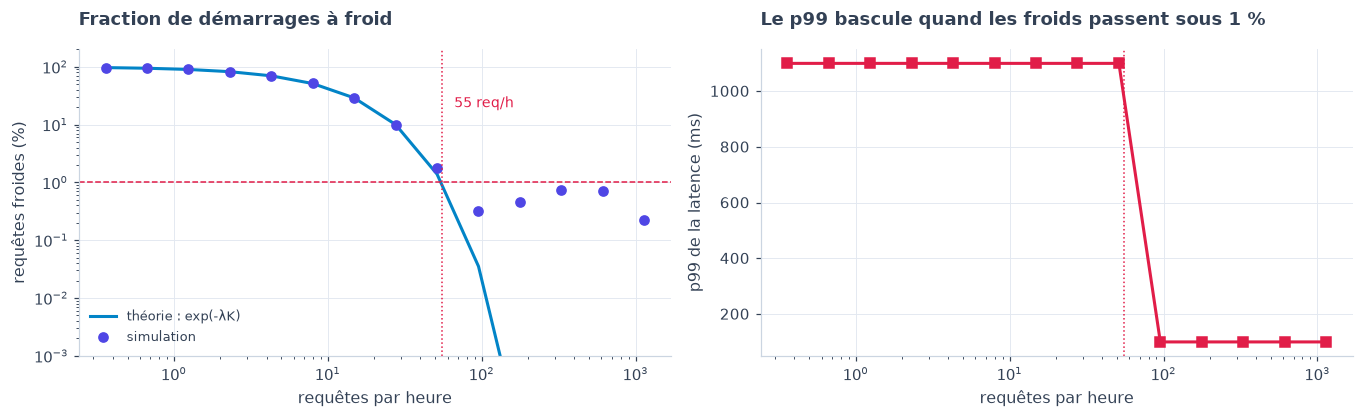

coût par requête : 1.87e-06 $ ; bascule : 16.0 M req/mois = 6.2 req/s


In [5]:
K, EX, CS = 300.0, 0.1, 1.0
lams = np.logspace(-4, -0.5, 14)
sim = []
for lam in lams:
    T = max(20_000 / lam, 3 * 86400)
    arr = np.cumsum(rng.exponential(1 / lam, int(lam * T * 1.2) + 50)); arr = arr[arr < T]
    out = ar.simulate_serverless(arr, EX, K, CS)
    sim.append((out["cold_fraction"], np.quantile(out["latency"], 0.99)))
sim = np.array(sim)
lam_1pct = math.log(100) / K
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9))
ax = axes[0]
ax.loglog(lams * 3600, np.exp(-lams * K) * 100, color=SKY, label="théorie : exp(-λK)")
ax.loglog(lams * 3600, np.maximum(sim[:, 0], 1e-5) * 100, "o", color=INDIGO, label="simulation")
ax.axhline(1, color=ROSE, ls="--", lw=1); ax.axvline(lam_1pct * 3600, color=ROSE, ls=":", lw=1)
ax.text(lam_1pct * 3600 * 1.2, 20, f"{lam_1pct * 3600:.0f} req/h", color=ROSE, fontsize=9)
ax.set_ylim(1e-3, 200); ax.set_xlabel("requêtes par heure"); ax.set_ylabel("requêtes froides (%)")
ax.set_title("Fraction de démarrages à froid"); ax.legend(fontsize=8.5)
ax = axes[1]
ax.semilogx(lams * 3600, sim[:, 1] * 1e3, "s-", color=ROSE)
ax.axvline(lam_1pct * 3600, color=ROSE, ls=":", lw=1)
ax.set_xlabel("requêtes par heure"); ax.set_ylabel("p99 de la latence (ms)")
ax.set_title("Le p99 bascule quand les froids passent sous 1 %")
plt.tight_layout(); plt.show()
per_req = EX * 0.0000167 + 0.2e-6
print(f"coût par requête : {per_req:.3g} $ ; bascule : {30 / per_req / 1e6:.1f} M req/mois "
      f"= {30 / per_req / (30 * 86400):.1f} req/s")

La simulation suit $e^{-\lambda K}$ à faible trafic, et le p99 passe de 1,1 s à 100 ms
précisément autour de 55 requêtes par heure, là où la fraction froide franchit 1 %.
Au-delà, la simulation s'écarte de la formule et plafonne vers 0,5 % : l'hypothèse « jamais
deux requêtes simultanées » cesse d'être vraie. Quand deux requêtes se chevauchent, la
seconde démarre une deuxième instance à froid, qui se refroidit ensuite faute de trafic,
et ainsi de suite. Cela reste sous le seuil de 1 % qui touche le p99.

> **À retenir.** Une requête serverless est froide si l'intervalle depuis la précédente
> dépasse la durée de maintien à chaud : $e^{-\lambda K}$ à faible trafic. Le p99 ne se
> débarrasse des démarrages à froid qu'au-delà de $\ln(100)/K$ requêtes par seconde ; le
> coût, lui, bascule en faveur d'une machine au-delà de quelques requêtes par seconde.

## Exercice 1.11 : l'intervalle optimal des points de reprise

**Énoncé.** Un calcul HPC tourne sur $n$ nœuds, chacun tombant en panne en moyenne une fois
tous les 5 ans (pannes indépendantes, exponentielles). Écrire un point de reprise coûte
$C$ = 6 minutes ; redémarrer après une panne coûte $R$ = 6 minutes. Une panne de n'importe
quel nœud arrête tout le calcul, qui repart du dernier point de reprise.

1. Quel est le temps moyen entre pannes $M$ du système de $n$ nœuds ?
2. En raisonnant au premier ordre (pannes rares devant l'intervalle $\tau$), montrer que
   la fraction de temps perdue vaut environ $C/\tau + \tau/(2M)$, et en déduire
   l'intervalle optimal $\tau^* = \sqrt{2\,C\,M}$ et l'efficacité $\approx 1 - \sqrt{2C/M}$.
3. Application à $n$ = 1 000, 10 000 et 100 000.
4. Vérifier par simulation.

**Rappels.** Points de reprise, formule de Young et Daly (`ar.young_daly_interval`,
`ar.simulate_checkpointing`) (cours 4, section 5 ; section *Cloud Computing Versus
Supercomputing*). Le minimum de $n$ exponentielles indépendantes de moyenne $m$ est
exponentiel de moyenne $m/n$.

**Solution.**

*1.* $M = 5 \times 8\,760 / n$ heures : 43,8 h pour 1 000 nœuds, 4,4 h pour 10 000,
0,44 h (26 minutes) pour 100 000.

*2.* Sur un intervalle de $\tau$ heures de calcul, on paie $C$ pour le point de reprise :
perte $C/\tau$ par unité de calcul. Une panne survient en moyenne toutes les $M$ heures ;
elle tombe à un instant uniforme de l'intervalle et fait perdre en moyenne $\tau/2$ de
calcul (plus $R$, indépendant de $\tau$) : perte $\tau/(2M)$ par unité de temps. On minimise
$g(\tau) = C/\tau + \tau/(2M)$ : $g'(\tau) = -C/\tau^2 + 1/(2M) = 0 \iff \tau^* = \sqrt{2CM}$,
et $g(\tau^*) = \sqrt{C/(2M)} + \sqrt{C/(2M)} = \sqrt{2C/M}$.

*3.* $C = 0{,}1$ h. Pour 1 000 nœuds : $\tau^* = \sqrt{2 \times 0{,}1 \times 43{,}8} = 2{,}96$ h,
perte $\approx 6{,}8\,\%$ (plus les redémarrages, $R/M$, 0,2 %). Pour 10 000 : $\tau^* = 0{,}94$ h,
perte $\approx 21\,\%$. Pour 100 000 : $\tau^* = 0{,}30$ h, perte prévue
$\approx 68\,\% + R/M = 23\,\%$, soit 90 % : le développement au premier ordre n'est plus
valable ($\tau^*$ n'est plus petit devant $M$, et les termes ne s'additionnent plus).

**Vérification par simulation.**

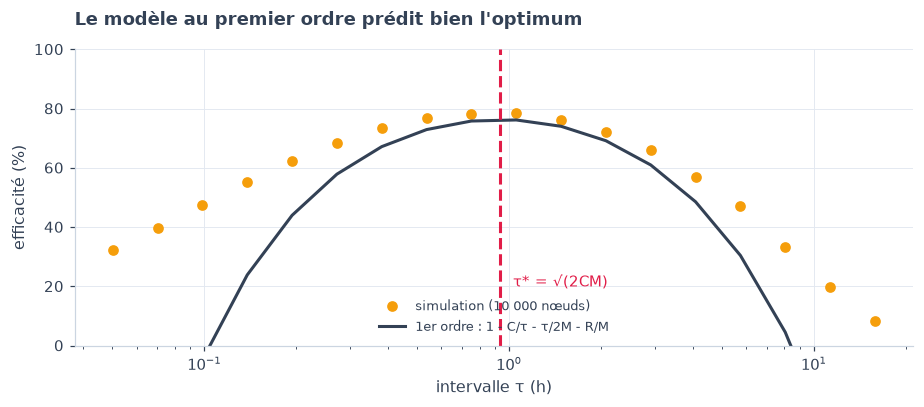

,M (h),τ* (h),efficacité au 1er ordre,efficacité simulée
nœuds,,,,
1000,43.800,2.960,0.930,0.930
10000,4.380,0.936,0.763,0.783
100000,0.438,0.296,0.096,0.373


In [6]:
C = R = 0.1
WORK = 300.0
rows = []
for n in [1000, 10_000, 100_000]:
    M = 5 * 8760 / n
    tau = ar.young_daly_interval(C, M)
    sim_eff = WORK / np.mean([ar.simulate_checkpointing(WORK, tau, C, R, M, seed=s) for s in range(20)])
    rows.append({"nœuds": n, "M (h)": M, "τ* (h)": tau, "efficacité au 1er ordre": 1 - math.sqrt(2 * C / M) - R / M,
                 "efficacité simulée": sim_eff})
tab = pd.DataFrame(rows).set_index("nœuds")

taus = np.logspace(-1.3, 1.2, 18)
M = 5 * 8760 / 10_000
eff = [WORK / np.mean([ar.simulate_checkpointing(WORK, t, C, R, M, seed=s) for s in range(10)]) for t in taus]
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.semilogx(taus, np.array(eff) * 100, "o", color=AMBER, label="simulation (10 000 nœuds)")
ax.semilogx(taus, (1 - C / taus - taus / (2 * M) - R / M) * 100, color=SLATE, label="1er ordre : 1 - C/τ - τ/2M - R/M")
ax.axvline(ar.young_daly_interval(C, M), color=ROSE, ls="--"); ax.text(ar.young_daly_interval(C, M) * 1.1, 20, "τ* = √(2CM)", color=ROSE)
ax.set_ylim(0, 100); ax.set_xlabel("intervalle τ (h)"); ax.set_ylabel("efficacité (%)")
ax.set_title("Le modèle au premier ordre prédit bien l'optimum"); ax.legend(fontsize=8.5, loc="lower center")
plt.tight_layout(); plt.show()
tab

Pour 1 000 et 10 000 nœuds, la simulation confirme l'efficacité prévue à quelques points
près, et la courbe atteint son maximum à $\tau^*$. Pour 100 000 nœuds, le développement au
premier ordre est pessimiste (10 % prévus, 37 % simulés : il compte deux fois des pertes
qui se recouvrent), mais le verdict ne change pas : près des deux tiers de la machine
sont gaspillés. À ce stade, il faut changer de stratégie (points de reprise plus rapides, en mémoire ou sur des nœuds voisins,
ou tolérance aux pannes sans arrêt global, comme dans le cloud).

> **À retenir.** L'intervalle optimal entre points de reprise vaut $\sqrt{2CM}$ et la
> perte minimale environ $\sqrt{2C/M}$ ; comme le MTBF du système est divisé par le nombre
> de nœuds, la stratégie « tout arrêter et repartir » s'effondre aux très grandes échelles.

## Exercice 1.12 : effacer dans un journal immuable

**Énoncé.** Une plateforme garde un journal d'événements de 1 milliard d'entrées de 500
octets (500 Go), au rythme de 50 millions de nouvelles entrées par jour. Elle reçoit 2 000
demandes d'effacement par jour ; un utilisateur a en moyenne 20 entrées. Un disque permet de
réécrire le journal à 500 Mo/s.

1. Compaction après chaque demande : combien d'octets réécrits par jour ? Est-ce
   faisable ?
2. Compaction groupée tous les $P$ jours : octets réécrits par jour, et délai moyen
   pendant lequel une donnée effacée reste lisible. Tracer le compromis pour $P$ de 1 à 30
   jours.
3. Crypto-shredding : 50 millions d'utilisateurs, une clé de 32 octets chacun, plus 32
   octets d'index. Taille du magasin de clés ? Que coûte un effacement ?
4. Mini-lab : vérifier sur un petit journal que les deux méthodes rendent les mêmes
   entrées lisibles, et comparer les octets réécrits.

**Rappels.** Compaction (`ar.compact_without`) et effacement cryptographique
(`ar.ShreddableLog`) (cours 5, section 2 ; section *Data Systems, Law, and Society*).

**Solution.**

*1.* Chaque compaction réécrit environ 500 Go : $2\,000 \times 500$ Go = 1 Po par jour,
soit $10^{15} / (5 \cdot 10^8) = 2 \cdot 10^6$ s de disque, **23 jours** de travail par
jour. Infaisable.

*2.* Une compaction tous les $P$ jours réécrit 500 Go, soit $500/P$ Go par jour
(17 minutes de disque par compaction). Une demande arrive à un instant uniforme entre deux
compactions : elle attend en moyenne $P/2$ jours. À $P = 1$ : 500 Go par jour et 12 h
d'attente moyenne ; à $P = 30$ : 17 Go par jour mais 15 jours d'attente. La loi demande
d'effacer « dans les meilleurs délais » (le RGPD parle d'un mois au plus pour répondre) :
une compaction quotidienne est un compromis raisonnable.

*3.* $5 \cdot 10^7 \times 64$ octets = **3,2 Go** : le magasin tient en mémoire d'une
machine. Un effacement supprime 64 octets et rend immédiatement illisibles les 20 entrées
de la personne, dans le journal **et** dans toutes ses copies. Le prix : chiffrer et
déchiffrer chaque entrée, une dépendance critique au magasin de clés (le perdre, c'est
perdre toutes les données ; il doit donc être répliqué et sauvegardé, mais sans garder les
clés détruites), et une interprétation juridique à valider.

**Vérification numérique et mini-lab.**

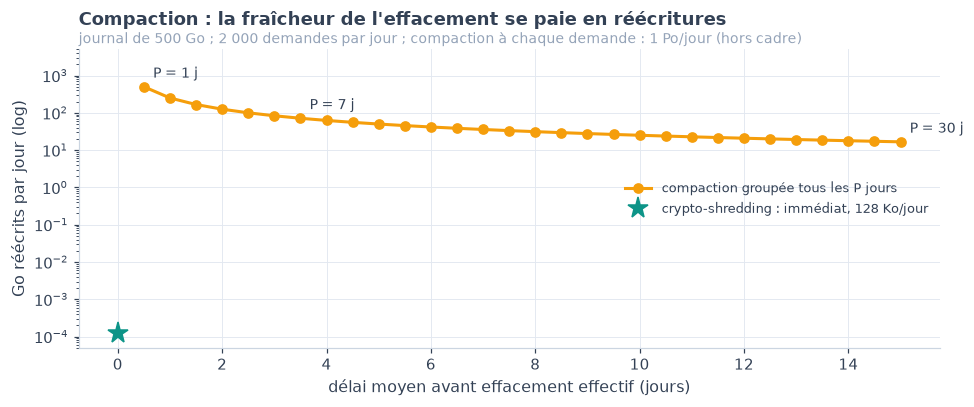

compaction à chaque demande : 1 Po/jour, soit 23 jours de disque par jour
magasin de clés : 3.2 Go


In [7]:
LOG = 500e9
P = np.arange(1, 31)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(P / 2, LOG / P / 1e9, "o-", color=AMBER, label="compaction groupée tous les P jours")
for p_ in (1, 7, 30):
    ax.annotate(f"P = {p_} j", (p_ / 2, LOG / p_ / 1e9), (6, 6), textcoords="offset points", fontsize=9)
ax.plot(0, 2000 * 64 / 1e9, "*", color=TEAL, ms=14, label="crypto-shredding : immédiat, 128 Ko/jour")
ax.set_yscale("log"); ax.set_ylim(5e-5, 5e3); ax.set_xlabel("délai moyen avant effacement effectif (jours)"); ax.set_ylabel("Go réécrits par jour (log)")
ax.set_title("Compaction : la fraîcheur de l'effacement se paie en réécritures")
subtitle(ax, "journal de 500 Go ; 2 000 demandes par jour ; compaction à chaque demande : 1 Po/jour (hors cadre)")
ax.legend(fontsize=8.5, loc="center right"); plt.tight_layout(); plt.show()
print(f"compaction à chaque demande : {2000 * LOG / 1e15:.0f} Po/jour, soit {2000 * LOG / 500e6 / 86400:.0f} jours de disque par jour")
print(f"magasin de clés : {50e6 * 64 / 1e9:.1f} Go")

In [8]:
users = [f"u{i}" for i in range(200)]
log = ar.ShreddableLog(seed=3)
plain = []
for i in range(4000):
    u = users[int(rng.integers(0, 200))]
    txt = f"événement {i} de {u}"
    log.append(u, txt)
    plain.append((u, txt.encode("utf-8")))
to_forget = users[:10]
total_rewritten = 0
for u in to_forget:                                   # compaction après chaque demande
    plain, rewritten = ar.compact_without(plain, u)
    total_rewritten += rewritten
shred_rewritten = sum(log.forget(u) for u in to_forget)
same = sorted(log.read()) == sorted((u, b.decode("utf-8")) for u, b in plain)
pd.DataFrame({"méthode": ["compaction après chaque demande", "crypto-shredding"],
              "entrées lisibles": [len(plain), len(log.read())],
              "octets réécrits pour 10 effacements": [total_rewritten, shred_rewritten],
              "taille du journal (octets)": [sum(len(b) for _, b in plain), log.size_bytes]}).set_index("méthode").assign(
    **{"mêmes entrées lisibles": same})

,entrées lisibles,octets réécrits pour 10 effacements,taille du journal (octets),mêmes entrées lisibles
méthode,,,,
compaction après chaque demande,3793,900644,88125,True
crypto-shredding,3793,0,92621,True


Les deux méthodes laissent exactement les mêmes entrées lisibles. La compaction a réécrit
près de dix fois la taille du journal pour dix effacements (chaque passe réécrit tout ce
qui reste) et a réduit sa taille ; le crypto-shredding n'a rien réécrit, et le journal
garde des octets chiffrés devenus illisibles.

> **À retenir.** Effacer dans un journal immuable par compaction coûte une réécriture
> complète par passe : on la groupe, au prix d'un délai d'effacement de l'ordre de la moitié
> de la période. Le crypto-shredding efface immédiatement et partout en détruisant une clé,
> mais déplace le problème vers une gestion des clés irréprochable.